# Training metrics

Plots for the metrics CSVs in the repo root (from `tools/collect_metrics.py`). All `*.csv` files there are
loaded, except `*.runs.csv`. Runs are overlaid, one colour each.

1. Summary table
2. Reward and judge
3. Where the step time goes
4. Rollout latency (stragglers)
5. Throughput and latency
6. Response length
7. Training health
8. Host memory

Panels whose metric is missing or always zero are left out.

In [1]:
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

ROOT   = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "collect_metrics.py").exists())
CSVS   = sorted(p for p in ROOT.glob("*.csv") if not p.name.endswith(".runs.csv"))  # or e.g. [ROOT / "metrics.csv"]
X      = "step"   # "step" or "hours" (wall clock since the run started)
SMOOTH = 0.0      # EMA weight, 0 = raw only. With smoothing on, the raw line is drawn faint behind it.

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "lines.linewidth": 1.6, "legend.frameon": False,
})

assert CSVS, f"no metrics CSV in {ROOT}"
df = pd.concat([pd.read_csv(p) for p in CSVS], ignore_index=True)
df = df[df["step"].notna()].drop_duplicates(["run", "step"], keep="last")
for c in ["time/step_start", "time/step_end"]:
    df[c] = pd.to_datetime(df[c])
df = df.sort_values(["run", "step"]).reset_index(drop=True)
print("loaded:", ", ".join(p.name for p in CSVS), f"-> {df['run'].nunique()} run(s), {len(df)} rows")
df["hours"] = df["time/elapsed_s"] / 3600
XLABEL = {"step": "step", "hours": "wall clock (h)"}[X]

runs = list(dict.fromkeys(df["run"]))
_short = {r: r.split("-", 2)[-1] for r in runs}
LABEL = {r: (_short[r] if list(_short.values()).count(_short[r]) == 1 else r) for r in runs}
RUN_COLOR = {r: (PALETTE[i] if i < len(PALETTE) else "#8a8984") for i, r in enumerate(runs)}

loaded: metrics.csv -> 1 run(s), 50 rows


In [2]:
def has(col):
    """Metric exists and is not constant zero."""
    return col in df and df[col].notna().any() and (df[col].fillna(0) != 0).any()

def ema(s, a):
    return s.ewm(alpha=1 - a, adjust=False).mean() if a > 0 else s

def line(ax, x, y, color, label=None, **kw):
    if SMOOTH > 0:
        ax.plot(x, y, color=color, alpha=0.25, lw=1)
        y = ema(y, SMOOTH)
    ax.plot(x, y, color=color, label=label, **kw)

def panel(ax, col, title, scale=1.0, pct=False, logy=False):
    for r, g in df.groupby("run", sort=False):
        g = g.dropna(subset=[col])
        line(ax, g[X], g[col] * scale, RUN_COLOR[r], LABEL[r])
    ax.set_title(title)
    if pct:
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    if logy:
        ax.set_yscale("log")

def run_legend(fig):
    if len(runs) > 1:
        h = [Line2D([], [], color=RUN_COLOR[r], lw=2) for r in runs]
        fig.legend(h, [LABEL[r] for r in runs], loc="lower center", ncol=min(len(runs), 4),
                   bbox_to_anchor=(0.5, 1.0))

def grid(specs, ncols=3, title=None):
    """specs: list of (column, title, {panel kwargs}). Missing/all-zero metrics are skipped."""
    specs = [s if len(s) == 3 else (*s, {}) for s in specs]
    skipped = [s[0] for s in specs if not has(s[0])]
    specs = [s for s in specs if has(s[0])]
    if not specs:
        print("nothing to plot"); return
    ncols = min(ncols, len(specs))
    nrows = math.ceil(len(specs) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 2.9 * nrows), squeeze=False, sharex=True)
    for ax, (col, ttl, kw) in zip(axes.flat, specs):
        panel(ax, col, ttl, **kw)
    for ax in axes.flat[len(specs):]:
        ax.set_visible(False)
    for i in range(len(specs)):  # bottom-most visible panel of each column gets the x axis
        if i + ncols >= len(specs):
            ax = axes.flat[i]
            ax.xaxis.set_tick_params(labelbottom=True)
            ax.set_xlabel(XLABEL)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
    run_legend(fig)
    fig.tight_layout()
    plt.show()
    if skipped:
        print("not shown (missing or all zero):", ", ".join(skipped))

## 1. Summary

In [3]:
def summarize(g):
    wall = (g["time/step_end"].max() - g["time/step_start"].min()).total_seconds()
    k = min(5, max(1, len(g) // 3))
    return pd.Series({
        "steps":                  len(g),
        "wall clock (h)":         wall / 3600,
        "step time, median (min)": g["timing/step"].median() / 60,
        "step time, max (min)":   g["timing/step"].max() / 60,
        "generate share":         g["timing/generate"].sum() / g["timing/step"].sum(),
        "untimed gaps (min)":     (wall - g["timing/step"].sum()) / 60,
        f"reward, first {k}":     g["reward/avg_raw_reward"].head(k).mean(),
        f"reward, last {k}":      g["reward/avg_raw_reward"].tail(k).mean(),
        f"pass@8, first {k}":     g["reward/avg_pass_at_8"].head(k).mean(),
        f"pass@8, last {k}":      g["reward/avg_pass_at_8"].tail(k).mean(),
        "train tok/s/GPU (mean)": g["trainer/tokens_per_second_per_gpu"].mean(),
    })

summary = df.groupby("run", sort=False).apply(summarize).T
summary.columns = [LABEL[r] for r in summary.columns]
summary.style.format("{:.3g}")

,so_openq_online_lr3e-6
steps,50
wall clock (h),38.7
"step time, median (min)",32.7
"step time, max (min)",233
generate share,0.815
untimed gaps (min),0.227
"reward, first 5",4.41
"reward, last 5",6.92
"pass@8, first 5",0.903
"pass@8, last 5",0.953


## 2. Reward and judge

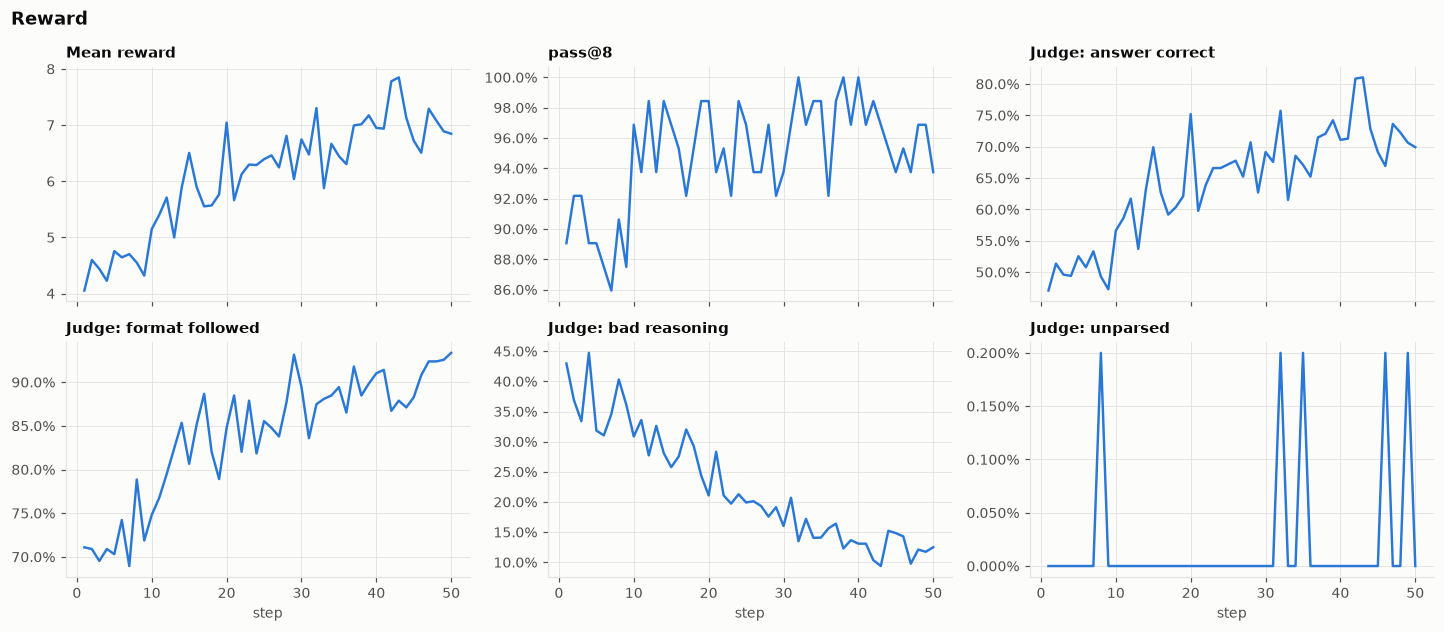

not shown (missing or all zero): environment/judge_skipped, environment/judge_bad_tool_calls


In [5]:
grid([
    ("reward/avg_raw_reward",              "Mean reward"),
    ("reward/avg_pass_at_8",               "pass@8", {"pct": True}),
    ("environment/judge_answer_correct",   "Judge: answer correct", {"pct": True}),
    ("environment/judge_format_followed",  "Judge: format followed", {"pct": True}),
    ("environment/judge_bad_reasoning",    "Judge: bad reasoning", {"pct": True}),
    ("environment/judge_unparsed",         "Judge: unparsed", {"pct": True}),
    ("environment/judge_skipped",          "Judge: skipped", {"pct": True}),
    ("environment/judge_bad_tool_calls",   "Judge: bad tool calls", {"pct": True}),
], title="Reward")

## 3. Where the step time goes

Left: each step split into phases, in minutes. Right: total over the run.
`other` is `timing/step` minus the timed phases. `cleanup_old_checkpoints` is already counted in `save_checkpoints`.

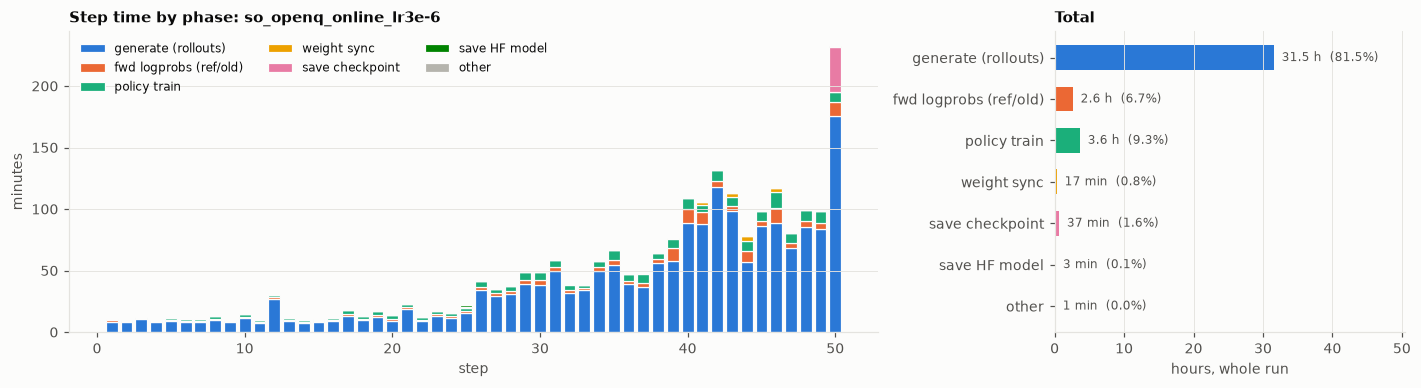

In [6]:
PHASES = [  # (column, label), stacking order bottom -> top
    ("timing/generate",                   "generate (rollouts)"),
    ("timing/fwd_logprobs_values_reward", "fwd logprobs (ref/old)"),
    ("timing/train_critic_and_policy",    "policy train"),
    ("timing/sync_weights",               "weight sync"),
    ("timing/save_checkpoints",           "save checkpoint"),
    ("timing/save_hf_model",              "save HF model"),
]
PHASES = [(c, l) for c, l in PHASES if c in df]

for r, g in df.groupby("run", sort=False):
    parts = pd.DataFrame({l: g[c].fillna(0) for c, l in PHASES})
    parts["other"] = (g["timing/step"] - parts.sum(axis=1)).clip(lower=0)
    parts = parts.loc[:, parts.sum() > 0] / 60
    colors = PALETTE[: parts.shape[1] - 1] + ["#b5b4ad"]

    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [3, 1.3]})
    bottom = np.zeros(len(g))
    for (name, vals), c in zip(parts.items(), colors):
        a.bar(g["step"], vals, bottom=bottom, color=c, label=name, width=0.8,
              edgecolor=SURFACE, linewidth=0.8)
        bottom += vals.values
    a.set_xlabel("step"); a.set_ylabel("minutes"); a.grid(axis="x", visible=False)
    a.set_title(f"Step time by phase: {LABEL[r]}")
    a.legend(loc="upper left", ncol=3, fontsize=8)

    tot = parts.sum()
    tot = tot / 60  # hours
    b.barh(tot.index[::-1], tot.values[::-1], color=colors[::-1], height=0.6)
    for y, (v, s) in enumerate(zip(tot.values[::-1], (tot / tot.sum()).values[::-1])):
        txt = f"{v:.1f} h" if v >= 1 else f"{v*60:.0f} min"
        b.text(v, y, f"  {txt}  ({s:.1%})", va="center", fontsize=8, color=INK2)
    b.set_xlim(0, tot.max() * 1.6); b.set_xlabel("hours, whole run")
    b.grid(axis="y", visible=False); b.set_title("Total")
    fig.tight_layout(); plt.show()

## 4. Rollout latency

Generation waits for the slowest trajectory in the batch. When `timing/generate` follows the max and not the
p90, a few slow trajectories set the step time.
Right: where an average trajectory spends its time.

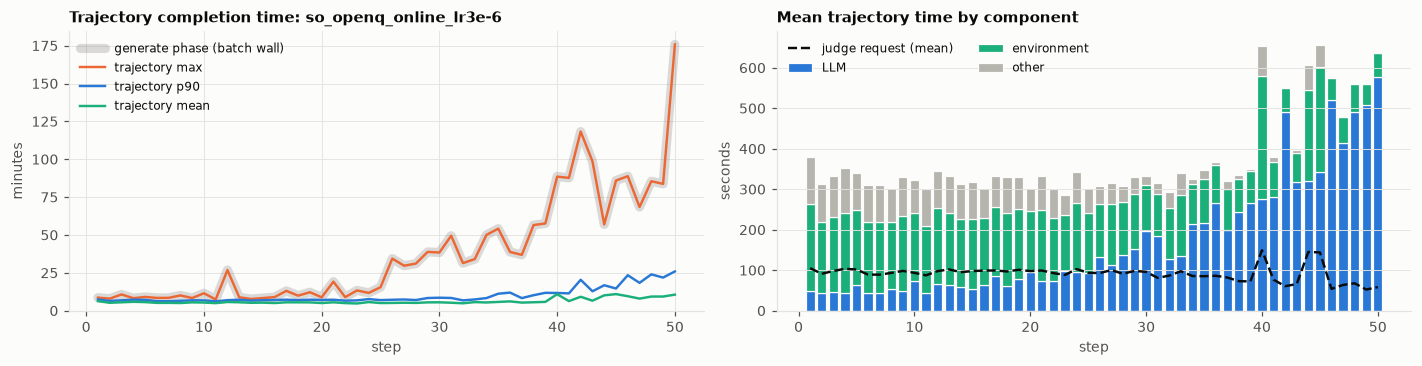

In [7]:
for r, g in df.groupby("run", sort=False):
    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.4))
    if "timing/generate" in g:  # wide faint band: the max line usually sits right on it
        a.plot(g[X], g["timing/generate"] / 60, color=INK2, lw=6, alpha=0.2, solid_capstyle="round",
               label="generate phase (batch wall)")
    for col, lab, c, ls in [
        ("generate/trajectory_time_completion_max", "trajectory max",             PALETTE[1], "-"),
        ("generate/trajectory_time_completion_p90", "trajectory p90",             PALETTE[0], "-"),
        ("generate/trajectory_time_completion_mean","trajectory mean",            PALETTE[2], "-"),
    ]:
        if col in g:
            a.plot(g[X], g[col] / 60, color=c, ls=ls, label=lab)
    a.set_ylabel("minutes"); a.set_xlabel(XLABEL); a.set_title(f"Trajectory completion time: {LABEL[r]}")
    a.set_ylim(bottom=0); a.legend(fontsize=8)

    comp = [("generate/trajectory_time_llm_mean", "LLM"),
            ("generate/trajectory_time_env_mean", "environment"),
            ("generate/trajectory_time_other_mean", "other")]
    bottom = np.zeros(len(g))
    for (col, lab), c in zip(comp, [PALETTE[0], PALETTE[2], "#b5b4ad"]):
        if col in g:
            b.bar(g["step"], g[col], bottom=bottom, color=c, label=lab, width=0.8, edgecolor=SURFACE, linewidth=0.8)
            bottom += g[col].fillna(0).values
    if "environment/judge_seconds" in g:
        b.plot(g["step"], g["environment/judge_seconds"], color=INK, ls="--", label="judge request (mean)")
    b.set_ylabel("seconds"); b.set_xlabel("step"); b.grid(axis="x", visible=False)
    b.set_title("Mean trajectory time by component"); b.legend(fontsize=8, ncol=2)
    fig.tight_layout(); plt.show()

## 5. Throughput and latency

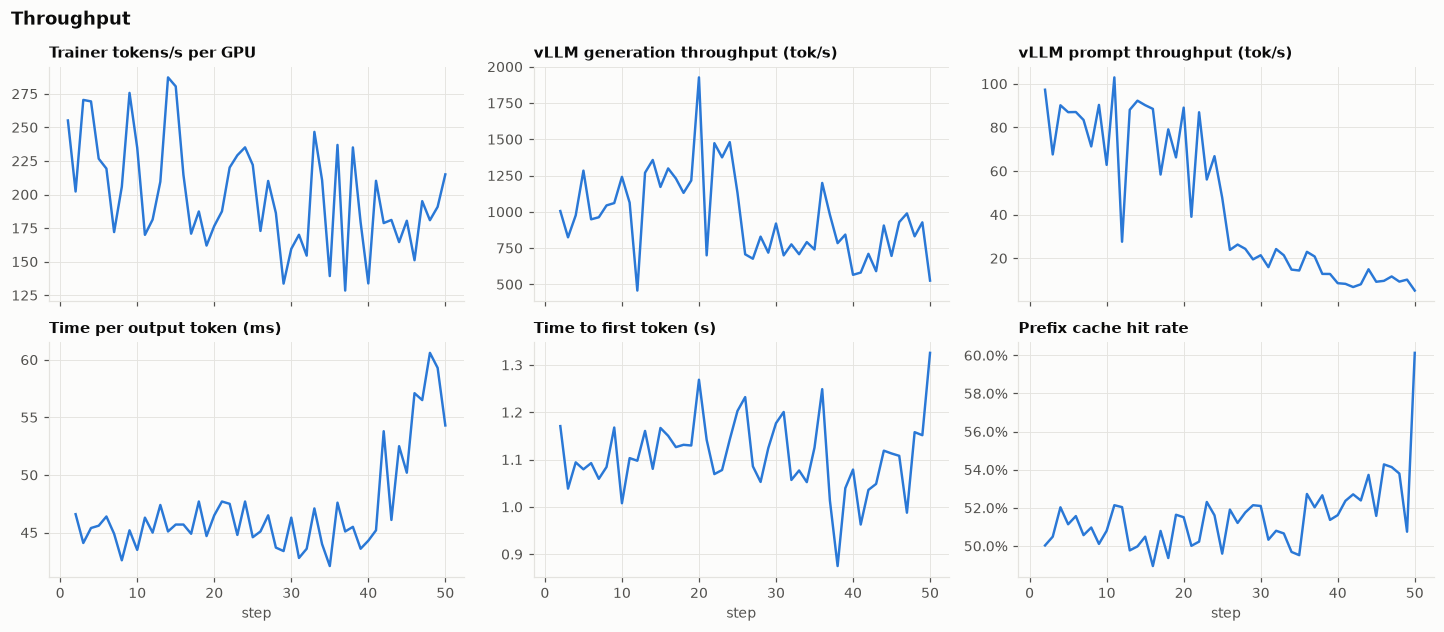

In [8]:
grid([
    ("trainer/tokens_per_second_per_gpu",       "Trainer tokens/s per GPU"),
    ("vllm/train/generation_throughput_tok_s",  "vLLM generation throughput (tok/s)"),
    ("vllm/train/prompt_throughput_tok_s",      "vLLM prompt throughput (tok/s)"),
    ("vllm/train/tpot_seconds_avg",             "Time per output token (ms)", {"scale": 1000}),
    ("vllm/train/ttft_seconds_avg",             "Time to first token (s)"),
    ("vllm/train/prefix_cache_hit_rate",        "Prefix cache hit rate", {"pct": True}),
], title="Throughput")

## 6. Response length

Right: solid lines are responses with non-zero reward, dashed lines are zero-reward responses.

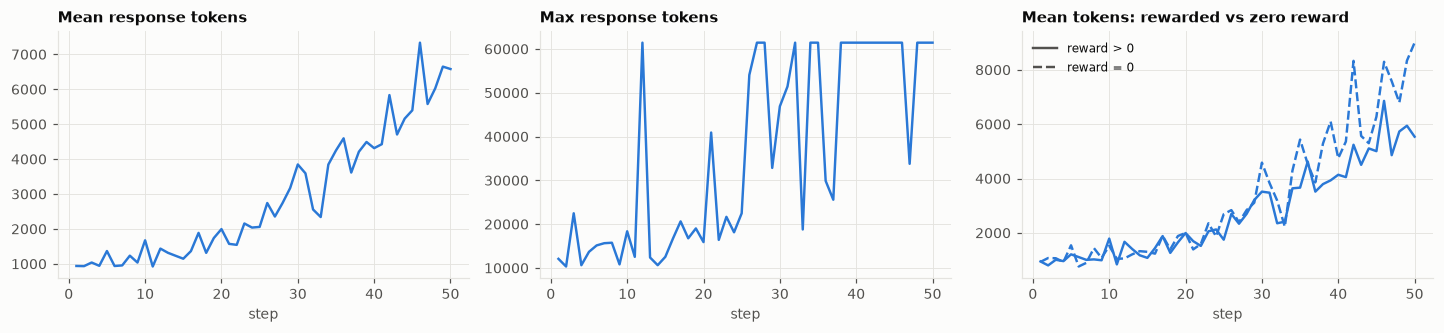

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.1), sharex=True)
panel(axes[0], "generate/avg_assistant_tokens", "Mean response tokens")
panel(axes[1], "generate/max_assistant_tokens", "Max response tokens")
for r, g in df.groupby("run", sort=False):
    line(axes[2], g[X], g["generate/avg_tokens_non_zero_rewards"], RUN_COLOR[r])
    line(axes[2], g[X], g["generate/avg_tokens_zero_rewards"], RUN_COLOR[r], ls="--")
axes[2].set_title("Mean tokens: rewarded vs zero reward")
axes[2].legend([Line2D([], [], color=INK2), Line2D([], [], color=INK2, ls="--")],
               ["reward > 0", "reward = 0"], fontsize=8)
for ax in axes: ax.set_xlabel(XLABEL)
run_legend(fig); fig.tight_layout(); plt.show()

## 7. Training health

LR is not plotted: it is a fixed schedule from the config (`policy/policy_lr`). `|logprob diff|` is the gap between vLLM rollout logprobs and trainer logprobs (off-policy / mismatch signal).

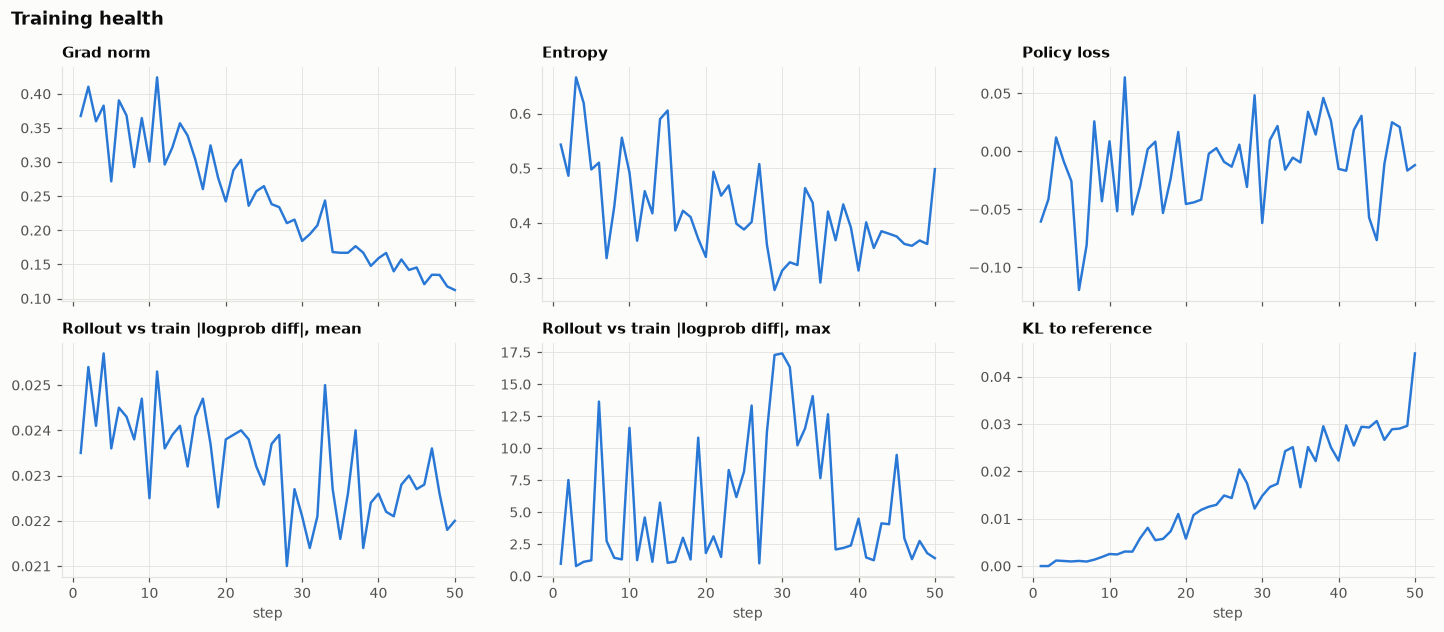

not shown (missing or all zero): policy/loss_metrics/clip_ratio


In [10]:
grid([
    ("policy/grad_norm",                         "Grad norm"),
    ("policy/policy_entropy",                    "Entropy"),
    ("policy/policy_loss",                       "Policy loss"),
    ("policy/rollout_train_logprobs_abs_diff_mean", "Rollout vs train |logprob diff|, mean"),
    ("policy/rollout_train_logprobs_abs_diff_max",  "Rollout vs train |logprob diff|, max"),
    ("policy/policy_kl",                         "KL to reference"),
    ("policy/loss_metrics/clip_ratio",           "Clip ratio", {"pct": True}),
], title="Training health")

## 8. Host memory (per node)

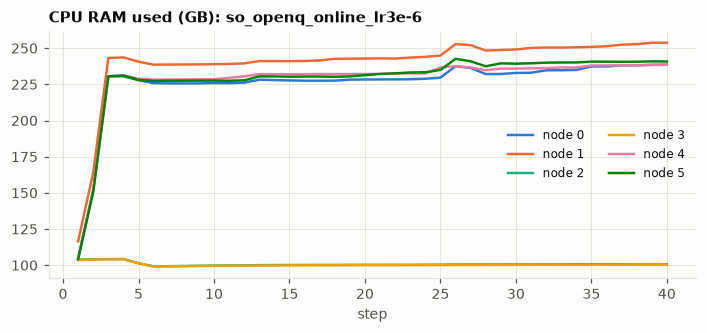

In [10]:
node_cols = sorted(c for c in df.columns if c.startswith("ray/node.") and c.endswith("cpu_ram_used_gb"))
if node_cols:
    fig, axes = plt.subplots(1, len(runs), figsize=(6.5 * len(runs), 3.1), squeeze=False)
    for ax, (r, g) in zip(axes[0], df.groupby("run", sort=False)):
        cols = [c for c in node_cols if g[c].notna().any()]
        for i, c in enumerate(cols):
            ax.plot(g[X], g[c], color=PALETTE[i] if i < len(PALETTE) else "#8a8984",
                    label=f"node {c.split('.')[1]}")
        ax.set_title(f"CPU RAM used (GB): {LABEL[r]}"); ax.set_xlabel(XLABEL)
        ax.legend(fontsize=8, ncol=2)
    fig.tight_layout(); plt.show()